# EcoVision — 01: TrashNet Dataset Exploration

**Week 1 | No training yet.** This notebook audits the *local* TrashNet dataset, visualizes class imbalance and previews images. Avoid committing dataset photos or private images.


## 1. Locate the repository and dataset

Place the original dataset under `ml/data/raw/trashnet/` with six class folders.


In [1]:
from pathlib import Path
import sys

current = Path.cwd().resolve()
repo_root = next((p for p in (current, *current.parents) if (p / "ml" / "src" / "dataset_audit.py").exists()), None)
if repo_root is None:
    raise RuntimeError("Open the notebook from inside the ecovision-flutter-ml repository.")
sys.path.insert(0, str(repo_root))
data_dir = repo_root / "ml" / "data" / "raw" / "trashnet"
print("Repository:", repo_root)
print("Dataset:", data_dir)
print("Present:", data_dir.exists())


Repository: E:\PROJECT\ecovision-flutter-ml
Dataset: E:\PROJECT\ecovision-flutter-ml\ml\data\raw\trashnet
Present: True


## 2. Validate image integrity and exact duplicates

Do **not** assume the upstream image count matches the downloaded copy. This audit verifies file readability and hashes exact duplicate files. It does not identify visual near-duplicates.


In [2]:
import pandas as pd
from ml.src.dataset_audit import audit_dataset, write_reports

summary, rows = audit_dataset(data_dir)
report_dir = repo_root / "ml" / "reports" / "generated"
write_reports(summary, rows, report_dir)
print("Integrity passed:", summary["integrity_passed"])
print("Valid images:", summary["valid_images"])
print("Invalid images:", len(summary["invalid_images"]))
print("Exact duplicate extra copies:", summary["exact_duplicate_extra_copies"])
print("Missing class folders:", summary["missing_classes"])
print("Saved audit reports to:", report_dir)
manifest = pd.DataFrame(rows)
manifest.head()


Integrity passed: False
Valid images: 2527
Invalid images: 0
Exact duplicate extra copies: 3
Missing class folders: []
Saved audit reports to: E:\PROJECT\ecovision-flutter-ml\ml\reports\generated


,path,label,valid,sha256,width,height,mode,error
0,cardboard/cardboard1.jpg,cardboard,True,9573fd98a5aca2ab9a4c5b9ebcdfa4dcf9719b216c2025...,512,384,RGB,
1,cardboard/cardboard10.jpg,cardboard,True,f460e7a993aabafef6839fa1fce1034c40713411beff32...,512,384,RGB,
2,cardboard/cardboard100.jpg,cardboard,True,13277fa7ae788f6f342a7d41ada36d4adcd20c58e504f2...,512,384,RGB,
3,cardboard/cardboard101.jpg,cardboard,True,2f3dafed35830c61c3464c876f7cfb82ad3b635078f630...,512,384,RGB,
4,cardboard/cardboard102.jpg,cardboard,True,5a88bce0103f59145f02b7fc0f50aa6dc3fbf29a1ffcae...,512,384,RGB,


## 3. Class distribution

An imbalanced dataset may make accuracy alone misleading. The `trash` class should be reviewed carefully.


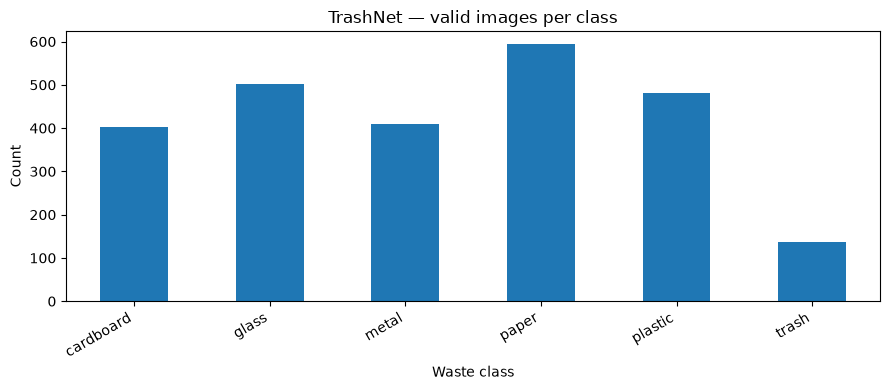

,count,percent
cardboard,403,15.95
glass,501,19.83
metal,410,16.22
paper,594,23.51
plastic,482,19.07
trash,137,5.42


In [3]:
import matplotlib.pyplot as plt

counts = pd.Series(summary["class_counts"], name="images")
ax = counts.plot.bar(figsize=(9, 4), title="TrashNet — valid images per class")
ax.set_xlabel("Waste class")
ax.set_ylabel("Count")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()
distribution = pd.DataFrame({"count": counts, "percent": (counts / counts.sum() * 100).round(2)})
distribution


## 4. Inspect sample images

These are data samples, not inference predictions. Note background, viewpoint, lighting, and potential ambiguous labels.


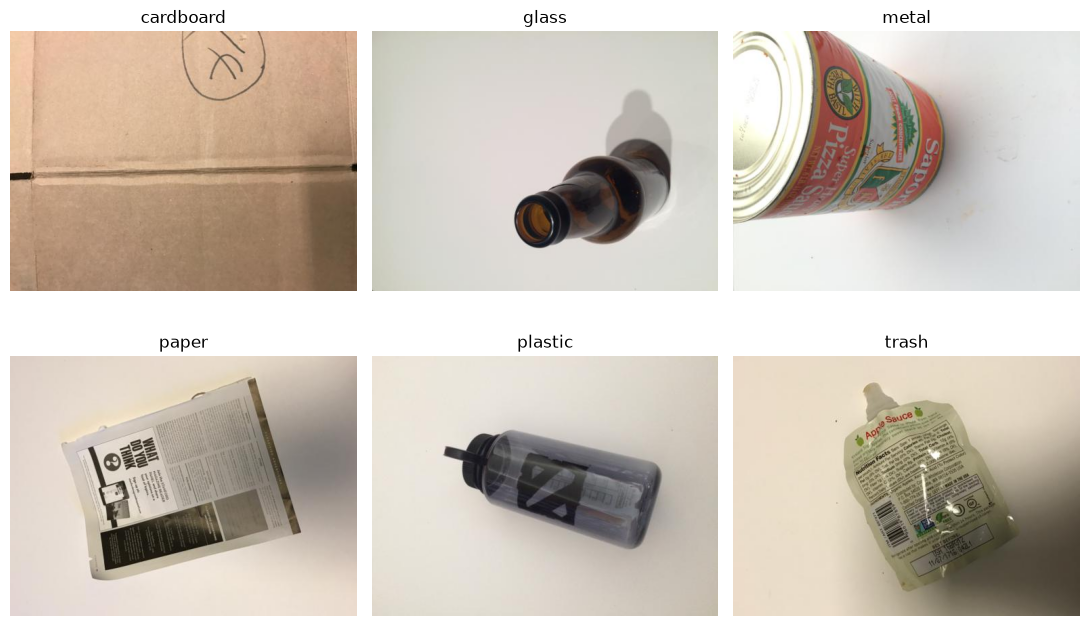

In [4]:
from PIL import Image

valid = manifest[manifest["valid"]].copy()
samples = valid.groupby("label", sort=True).head(1)
fig, axes = plt.subplots(2, 3, figsize=(11, 7))
for ax in axes.flat:
    ax.axis("off")
for ax, (_, rec) in zip(axes.flat, samples.iterrows()):
    with Image.open(data_dir / rec["path"]) as im:
        ax.imshow(im.convert("RGB"))
    ax.set_title(rec["label"])
    ax.axis("off")
plt.tight_layout()
plt.show()


## 5. Document actual findings (fill after execution)

- **Valid image count:** _pending local run_
- **Corrupted/invalid images:** _pending local run_
- **Exact duplicates:** _pending local run_
- **Potential near-duplicates:** _requires manual inspection_
- **Possible mislabeled or ambiguous samples:** _requires manual inspection_
- **Class imbalance / potential bias:** _pending observation_
- **Next step:** Review data leakage risks before a 70/15/15 stratified split. Do not augment validation or test samples.


Jumlah pasangan/grup duplikat: 3


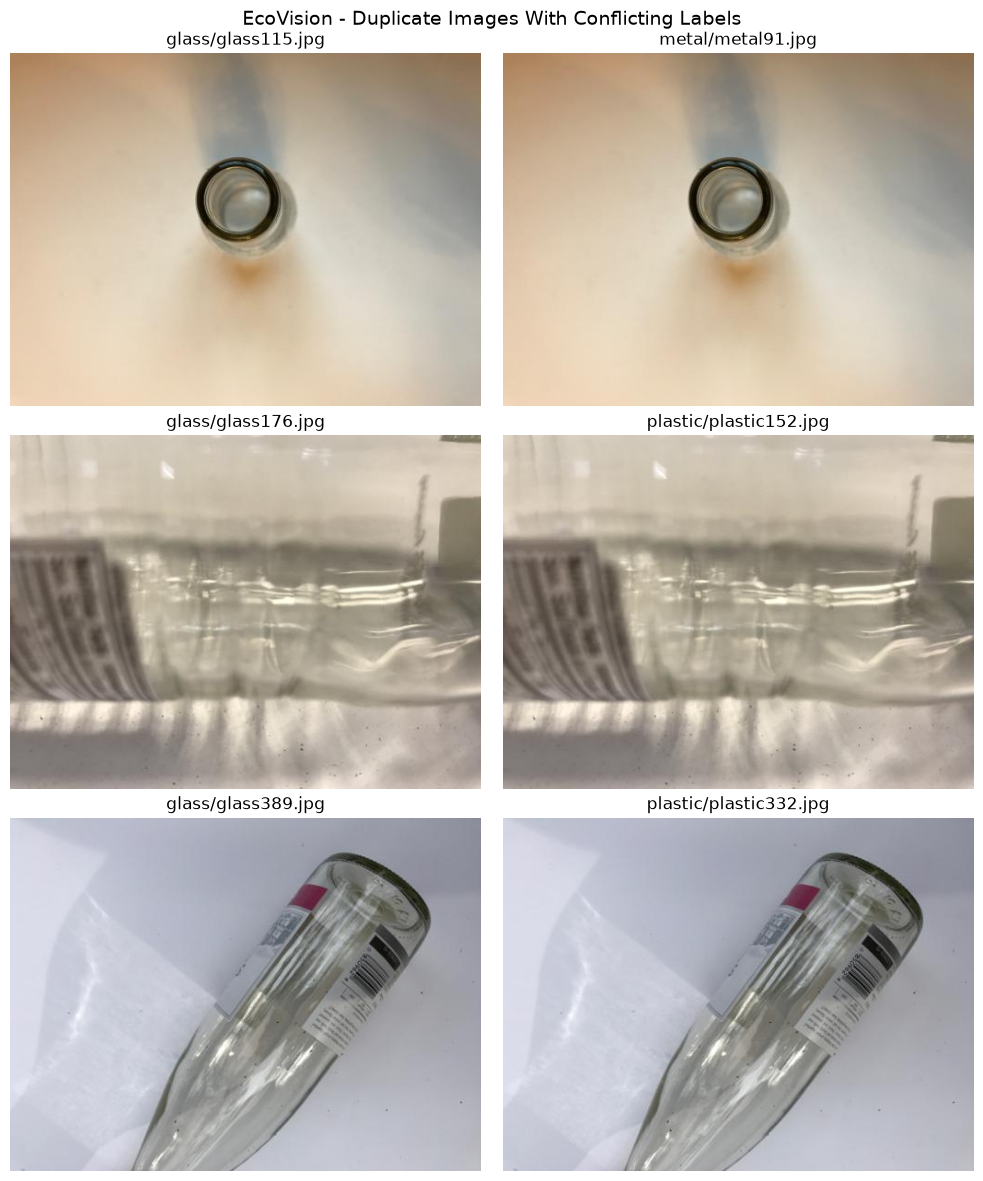

In [5]:

from PIL import Image
import matplotlib.pyplot as plt

# Ambil daftar gambar duplikat dari hasil audit
duplicate_groups = summary["exact_duplicate_groups"]

print(f"Jumlah pasangan/grup duplikat: {len(duplicate_groups)}")

fig, axes = plt.subplots(
    len(duplicate_groups),
    2,
    figsize=(10, 12),
    squeeze=False
)

for row, group in enumerate(duplicate_groups):
    for col, relative_path in enumerate(group[:2]):
        image_path = data_dir / relative_path

        with Image.open(image_path) as img:
            axes[row, col].imshow(img.convert("RGB"))

        axes[row, col].set_title(relative_path)
        axes[row, col].axis("off")

plt.suptitle(
    "EcoVision - Duplicate Images With Conflicting Labels",
    fontsize=14
)

plt.tight_layout()
plt.show()


In [6]:

import pandas as pd

# Keputusan berdasarkan manual visual review
decisions = [
    {
        "keep_path": "glass/glass115.jpg",
        "exclude_path": "metal/metal91.jpg",
        "reviewed_label": "glass",
        "status": "provisional_visual_review",
    },
    {
        "keep_path": "plastic/plastic152.jpg",
        "exclude_path": "glass/glass176.jpg",
        "reviewed_label": "plastic",
        "status": "provisional_visual_review",
    },
    {
        "keep_path": "glass/glass389.jpg",
        "exclude_path": "plastic/plastic332.jpg",
        "reviewed_label": "glass",
        "status": "provisional_visual_review",
    },
]

# Pastikan pasangan sesuai hasil audit asli
expected_groups = {
    frozenset((d["keep_path"], d["exclude_path"]))
    for d in decisions
}
actual_groups = {
    frozenset(group)
    for group in summary["exact_duplicate_groups"]
}

assert actual_groups == expected_groups, (
    "Duplicate groups tidak sesuai. Review ulang!"
)

# Keluarkan salinan yang berlabel konflik
exclude_paths = {d["exclude_path"] for d in decisions}

clean_manifest = manifest.loc[
    manifest["valid"] &
    ~manifest["path"].isin(exclude_paths)
].copy()

# Validasi hasil cleaning
assert len(clean_manifest) == 2524
assert clean_manifest["sha256"].is_unique

# Simpan manifest tanpa mengubah dataset asli
clean_path = report_dir / "dataset_manifest_clean.csv"
clean_manifest.to_csv(clean_path, index=False)

# Simpan keputusan cleaning agar terdokumentasi
decision_path = repo_root / "ml" / "data" / "cleaning_decisions.csv"
pd.DataFrame(decisions).to_csv(decision_path, index=False)

print("Original images:", summary["valid_images"])
print("Clean images:", len(clean_manifest))
print("Excluded images:", len(exclude_paths))
print("Duplicate hashes remaining:",
      clean_manifest["sha256"].duplicated().sum())

print("\nClass distribution:")
print(clean_manifest["label"].value_counts().sort_index())

print("\nSaved:", clean_path)
print("Saved:", decision_path)


Original images: 2527
Clean images: 2524
Excluded images: 3
Duplicate hashes remaining: 0

Class distribution:
label
cardboard    403
glass        500
metal        409
paper        594
plastic      481
trash        137
Name: count, dtype: int64

Saved: E:\PROJECT\ecovision-flutter-ml\ml\reports\generated\dataset_manifest_clean.csv
Saved: E:\PROJECT\ecovision-flutter-ml\ml\data\cleaning_decisions.csv


In [7]:

from sklearn.model_selection import train_test_split
import pandas as pd

RANDOM_STATE = 42

# Urutkan agar hasil konsisten saat notebook dijalankan ulang
dataset = clean_manifest.sort_values("path").reset_index(drop=True)

# Tahap 1: pisahkan 15% untuk test set
train_val, test_df = train_test_split(
    dataset,
    test_size=0.15,
    stratify=dataset["label"],
    random_state=RANDOM_STATE
)

# Tahap 2: ambil 15% dari total untuk validation
train_df, val_df = train_test_split(
    train_val,
    test_size=0.15 / 0.85,
    stratify=train_val["label"],
    random_state=RANDOM_STATE
)

# Validasi jumlah data
assert len(train_df) + len(val_df) + len(test_df) == len(dataset)

# Validasi tidak ada file identik antar-split
splits = {
    "train": train_df,
    "val": val_df,
    "test": test_df,
}

for name_a, df_a in splits.items():
    for name_b, df_b in splits.items():
        if name_a >= name_b:
            continue

        assert set(df_a["path"]).isdisjoint(df_b["path"])
        assert set(df_a["sha256"]).isdisjoint(df_b["sha256"])

# Simpan manifest setiap subset
split_dir = report_dir / "splits"
split_dir.mkdir(parents=True, exist_ok=True)

for name, df in splits.items():
    df.to_csv(split_dir / f"{name}.csv", index=False)

# Ringkasan distribusi kelas
distribution = pd.DataFrame({
    name: df["label"].value_counts().sort_index()
    for name, df in splits.items()
}).fillna(0).astype(int)

distribution["total"] = distribution.sum(axis=1)

print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))
print("Total:", len(dataset))

print("\nClass distribution:")
print(distribution)

print("\nExact duplicate leakage: NONE")
print("Saved to:", split_dir)


Training: 1766
Validation: 379
Testing: 379
Total: 2524

Class distribution:
           train  val  test  total
label                             
cardboard    282   60    61    403
glass        350   75    75    500
metal        286   62    61    409
paper        416   89    89    594
plastic      337   72    72    481
trash         95   21    21    137

Exact duplicate leakage: NONE
Saved to: E:\PROJECT\ecovision-flutter-ml\ml\reports\generated\splits


In [8]:

from pathlib import Path
from PIL import Image, ImageOps
from scipy.fft import dctn
import numpy as np
import pandas as pd

# Perceptual hash: 64-bit pHash
def calculate_phash(image_path):
    with Image.open(image_path) as image:
        image = ImageOps.exif_transpose(image)
        image = image.convert("L").resize((32, 32))
        pixels = np.asarray(image, dtype=np.float32)

    coefficients = dctn(pixels, norm="ortho")[:8, :8].flatten()
    median = np.median(coefficients[1:])

    bits = coefficients > median
    bits[0] = False

    value = 0
    for bit in bits:
        value = (value << 1) | int(bit)

    return value


# Gabungkan manifest dengan informasi split
combined = pd.concat([
    train_df.assign(split="train"),
    val_df.assign(split="val"),
    test_df.assign(split="test")
], ignore_index=True)

# Hitung perceptual hash setiap gambar
records = []

for row in combined.itertuples():
    records.append({
        "path": row.path,
        "label": row.label,
        "split": row.split,
        "phash": calculate_phash(data_dir / row.path)
    })

# Cari gambar mirip yang berada di split berbeda
THRESHOLD = 6
candidates = []

for i, first in enumerate(records):
    for second in records[i + 1:]:
        if first["split"] == second["split"]:
            continue

        distance = (
            first["phash"] ^ second["phash"]
        ).bit_count()

        if distance <= THRESHOLD:
            candidates.append({
                "image_a": first["path"],
                "split_a": first["split"],
                "image_b": second["path"],
                "split_b": second["split"],
                "hamming_distance": distance
            })

results = pd.DataFrame(candidates)

if not results.empty:
    results = results.sort_values("hamming_distance")
    display(results.head(20))

    output_path = report_dir / "near_duplicate_candidates.csv"
    results.to_csv(output_path, index=False)
    print("Saved:", output_path)

print("Total images checked:", len(records))
print("Near-duplicate candidates:", len(candidates))


,image_a,split_a,image_b,split_b,hamming_distance
7,paper/paper390.jpg,train,paper/paper185.jpg,val,2
4,paper/paper466.jpg,train,paper/paper459.jpg,val,2
11,paper/paper101.jpg,train,paper/paper108.jpg,test,2
9,cardboard/cardboard361.jpg,train,cardboard/cardboard15.jpg,val,2
18,paper/paper2.jpg,val,paper/paper40.jpg,test,2
13,paper/paper451.jpg,train,paper/paper345.jpg,val,4
6,paper/paper89.jpg,train,paper/paper474.jpg,val,4
10,paper/paper549.jpg,train,paper/paper176.jpg,test,4
5,paper/paper123.jpg,train,paper/paper547.jpg,test,4
0,plastic/plastic350.jpg,train,plastic/plastic105.jpg,test,6


Saved: E:\PROJECT\ecovision-flutter-ml\ml\reports\generated\near_duplicate_candidates.csv
Total images checked: 2524
Near-duplicate candidates: 19


In [13]:

from PIL import Image
import matplotlib.pyplot as plt

# Urutkan kandidat berdasarkan tingkat kemiripan
review_candidates = results.sort_values(
    ["hamming_distance", "image_a", "image_b"]
).reset_index(drop=True)

# Tampilkan 5 pasangan per halaman
PER_PAGE = 5
PAGE = 4

start = PAGE * PER_PAGE
batch = review_candidates.iloc[start:start + PER_PAGE]

if batch.empty:
    print("Tidak ada kandidat pada halaman ini.")
else:
    fig, axes = plt.subplots(
        len(batch), 2,
        figsize=(12, 3.5 * len(batch)),
        squeeze=False
    )

    for i, (_, row) in enumerate(batch.iterrows()):
        for col, suffix in enumerate(["a", "b"]):
            image_path = data_dir / row[f"image_{suffix}"]

            with Image.open(image_path) as img:
                axes[i, col].imshow(img.convert("RGB"))

            axes[i, col].set_title(
                f"{row[f'image_{suffix}']}\n"
                f"Split: {row[f'split_{suffix}']}"
            )
            axes[i, col].axis("off")

        axes[i, 0].set_ylabel(
            f"pHash distance: {row['hamming_distance']}",
            fontsize=10
        )

    plt.suptitle(
        f"EcoVision - Near-Duplicate Review Page {PAGE + 1}",
        fontsize=15
    )
    plt.tight_layout()
    plt.show()

print(f"Showing candidates {start + 1} to "
      f"{min(start + PER_PAGE, len(review_candidates))} "
      f"of {len(review_candidates)}")


Tidak ada kandidat pada halaman ini.
Showing candidates 21 to 19 of 19


In [14]:

import pandas as pd

# Keputusan manual dari review Page 1-4
review_pairs = [
    # Page 1
    ("cardboard/cardboard361.jpg", "cardboard/cardboard15.jpg", "group"),
    ("paper/paper101.jpg", "paper/paper108.jpg", "group"),
    ("paper/paper2.jpg", "paper/paper40.jpg", "group"),
    ("paper/paper390.jpg", "paper/paper185.jpg", "group"),
    ("paper/paper466.jpg", "paper/paper459.jpg", "group"),

    # Page 2
    ("paper/paper123.jpg", "paper/paper547.jpg", "group"),
    ("paper/paper451.jpg", "paper/paper345.jpg", "group"),
    ("paper/paper549.jpg", "paper/paper176.jpg", "group"),
    ("paper/paper89.jpg", "paper/paper474.jpg", "group"),
    ("glass/glass127.jpg", "plastic/plastic11.jpg", "different"),

    # Page 3
    ("metal/metal11.jpg", "metal/metal221.jpg", "group"),
    ("metal/metal149.jpg", "metal/metal9.jpg", "group"),
    ("metal/metal149.jpg", "plastic/plastic135.jpg", "different"),
    ("metal/metal165.jpg", "metal/metal166.jpg", "uncertain_group"),
    ("metal/metal76.jpg", "metal/metal394.jpg", "group"),

    # Page 4
    ("plastic/plastic293.jpg", "plastic/plastic384.jpg", "group"),
    ("plastic/plastic350.jpg", "plastic/plastic105.jpg", "group"),
    ("trash/trash127.jpg", "plastic/plastic131.jpg", "different"),
    ("trash/trash133.jpg", "plastic/plastic481.jpg", "different"),
]

review_df = pd.DataFrame(
    review_pairs,
    columns=["image_a", "image_b", "decision"]
)

# Pastikan semua kandidat hasil pHash sudah direview
detected_pairs = {
    frozenset((r.image_a, r.image_b))
    for r in results.itertuples()
}

reviewed_pairs = {
    frozenset((r.image_a, r.image_b))
    for r in review_df.itertuples()
}

assert len(review_df) == 19
assert detected_pairs == reviewed_pairs, (
    "Daftar review tidak sesuai kandidat pHash!"
)

# Simpan keputusan dalam repository
review_path = (
    repo_root / "ml" / "data" / "near_duplicate_review.csv"
)
review_df.to_csv(review_path, index=False)

print(review_df["decision"].value_counts())
print("\nSaved:", review_path)


decision
group              14
different           4
uncertain_group     1
Name: count, dtype: int64

Saved: E:\PROJECT\ecovision-flutter-ml\ml\data\near_duplicate_review.csv


In [15]:

from sklearn.model_selection import train_test_split

RANDOM_STATE = 42

grouped_manifest = clean_manifest.copy()
grouped_manifest = grouped_manifest.sort_values(
    "path"
).reset_index(drop=True)

# Union-Find untuk mengelompokkan gambar
parent = {
    path: path for path in grouped_manifest["path"]
}

def find(path):
    while parent[path] != path:
        parent[path] = parent[parent[path]]
        path = parent[path]
    return path

def union(a, b):
    root_a = find(a)
    root_b = find(b)

    if root_a != root_b:
        parent[max(root_a, root_b)] = min(root_a, root_b)

# Gabungkan pasangan yang wajib berada di split sama
for row in review_df.itertuples():
    if row.decision in ("group", "uncertain_group"):
        assert row.image_a in parent
        assert row.image_b in parent
        union(row.image_a, row.image_b)

grouped_manifest["group_id"] = (
    grouped_manifest["path"].map(find)
)

# Satu grup tidak boleh memiliki kelas yang berbeda
label_counts = grouped_manifest.groupby(
    "group_id"
)["label"].nunique()

assert (label_counts == 1).all(), (
    "Ada grup dengan label berbeda!"
)

# Satu baris mewakili satu grup
groups = grouped_manifest.groupby(
    "group_id", as_index=False
).agg(
    label=("label", "first"),
    n_images=("path", "size")
)

# Stratified splitting berdasarkan grup, bukan gambar
train_val_g, test_g = train_test_split(
    groups,
    test_size=0.15,
    stratify=groups["label"],
    random_state=RANDOM_STATE
)

train_g, val_g = train_test_split(
    train_val_g,
    test_size=0.15 / 0.85,
    stratify=train_val_g["label"],
    random_state=RANDOM_STATE
)

# Petakan setiap grup ke subset
group_to_split = {}

for split_name, frame in [
    ("train", train_g),
    ("val", val_g),
    ("test", test_g),
]:
    for group_id in frame["group_id"]:
        group_to_split[group_id] = split_name

grouped_manifest["split"] = (
    grouped_manifest["group_id"].map(group_to_split)
)

assert grouped_manifest["split"].notna().all()

# Simpan manifest baru, jangan timpa split lama
grouped_split_dir = report_dir / "splits_grouped"
grouped_split_dir.mkdir(parents=True, exist_ok=True)

final_splits = {}

for name in ("train", "val", "test"):
    frame = grouped_manifest[
        grouped_manifest["split"] == name
    ].copy()

    final_splits[name] = frame
    frame.to_csv(
        grouped_split_dir / f"{name}.csv",
        index=False
    )

# Validasi tidak ada kebocoran grup maupun hash identik
for a, b in [
    ("train", "val"),
    ("train", "test"),
    ("val", "test"),
]:
    assert set(
        final_splits[a]["group_id"]
    ).isdisjoint(final_splits[b]["group_id"])

    assert set(
        final_splits[a]["sha256"]
    ).isdisjoint(final_splits[b]["sha256"])

assert sum(
    len(df) for df in final_splits.values()
) == len(clean_manifest)

# Tampilkan hasil aktual
distribution = pd.DataFrame({
    name: df["label"].value_counts()
    for name, df in final_splits.items()
}).fillna(0).astype(int).sort_index()

distribution["total"] = distribution.sum(axis=1)

print("Total groups:", len(groups))
print("Total images:", len(grouped_manifest))

for name, df in final_splits.items():
    percentage = 100 * len(df) / len(grouped_manifest)
    print(f"{name}: {len(df)} images ({percentage:.2f}%)")

print("\nClass distribution:")
print(distribution)

print("\nCross-split group leakage: NONE")
print("Cross-split exact hash leakage: NONE")
print("Saved to:", grouped_split_dir)


Total groups: 2509
Total images: 2524
train: 1767 images (70.01%)
val: 377 images (14.94%)
test: 380 images (15.06%)

Class distribution:
           train  val  test  total
label                             
cardboard    283   60    60    403
glass        350   75    75    500
metal        286   61    62    409
paper        417   88    89    594
plastic      336   72    73    481
trash         95   21    21    137

Cross-split group leakage: NONE
Cross-split exact hash leakage: NONE
Saved to: E:\PROJECT\ecovision-flutter-ml\ml\reports\generated\splits_grouped


In [17]:

# EcoVision - Verify cross-split near-duplicates
# after group-aware splitting

import pandas as pd

THRESHOLD = 6

# Gunakan pHash yang sudah dihitung sebelumnya
phash_by_path = {
    item["path"]: int(item["phash"])
    for item in records
}

assert set(phash_by_path) == set(grouped_manifest["path"])

# Hasil keputusan review manual sebelumnya
review_lookup = {
    frozenset((row.image_a, row.image_b)): row.decision
    for row in review_df.itertuples()
}

images = grouped_manifest[
    ["path", "split", "group_id"]
].to_dict("records")

cross_split_candidates = []

for i, first in enumerate(images):
    for second in images[i + 1:]:

        if first["split"] == second["split"]:
            continue

        distance = (
            phash_by_path[first["path"]]
            ^ phash_by_path[second["path"]]
        ).bit_count()

        if distance <= THRESHOLD:
            pair = frozenset((
                first["path"],
                second["path"]
            ))

            decision = review_lookup.get(
                pair, "not_reviewed"
            )

            cross_split_candidates.append({
                "image_a": first["path"],
                "split_a": first["split"],
                "image_b": second["path"],
                "split_b": second["split"],
                "distance": distance,
                "review_status": decision
            })

verification_df = pd.DataFrame(
    cross_split_candidates,
    columns=[
        "image_a", "split_a", "image_b",
        "split_b", "distance", "review_status"
    ]
)

# Pastikan grup yang wajib bersatu tidak terpisah
assert not verification_df["review_status"].isin(
    ["group", "uncertain_group"]
).any(), "Ada grup yang terpisah!"

# Kandidat yang belum selesai diperiksa
needs_review = verification_df[
    verification_df["review_status"] == "not_reviewed"
]

output_path = (
    report_dir / "grouped_split_phash_verification.csv"
)
verification_df.to_csv(output_path, index=False)

print("Total images:", len(images))
print("Cross-split pHash candidates:", len(verification_df))
print("Already reviewed as different:",
      (verification_df["review_status"] == "different").sum())
print("New candidates requiring review:", len(needs_review))

if needs_review.empty:
    print("\nNo unresolved candidates at threshold <= 6.")
else:
    display(needs_review.sort_values("distance"))

print("\nSaved:", output_path)


Total images: 2524
Cross-split pHash candidates: 15
Already reviewed as different: 3
New candidates requiring review: 12


,image_a,split_a,image_b,split_b,distance,review_status
7,paper/paper305.jpg,test,paper/paper308.jpg,train,0,not_reviewed
0,cardboard/cardboard386.jpg,train,cardboard/cardboard72.jpg,test,2,not_reviewed
4,paper/paper152.jpg,test,paper/paper392.jpg,val,2,not_reviewed
2,metal/metal155.jpg,train,metal/metal6.jpg,test,2,not_reviewed
8,paper/paper314.jpg,train,paper/paper53.jpg,val,2,not_reviewed
5,paper/paper246.jpg,val,paper/paper349.jpg,train,2,not_reviewed
10,paper/paper522.jpg,test,paper/paper534.jpg,train,2,not_reviewed
3,paper/paper135.jpg,val,paper/paper496.jpg,train,4,not_reviewed
9,paper/paper457.jpg,train,paper/paper553.jpg,test,4,not_reviewed
6,paper/paper265.jpg,val,paper/paper408.jpg,train,6,not_reviewed



Saved: E:\PROJECT\ecovision-flutter-ml\ml\reports\generated\grouped_split_phash_verification.csv


In [18]:

# EcoVision - Global Near-Duplicate Audit
# Audit seluruh dataset, tanpa memperhatikan split

import pandas as pd

THRESHOLD = 6

all_records = sorted(
    records,
    key=lambda item: item["path"]
)

global_candidates = []

for i, first in enumerate(all_records):
    for second in all_records[i + 1:]:
        distance = (
            int(first["phash"]) ^ int(second["phash"])
        ).bit_count()

        if distance <= THRESHOLD:
            global_candidates.append({
                "image_a": first["path"],
                "image_b": second["path"],
                "distance": distance,
            })

global_df = pd.DataFrame(
    global_candidates,
    columns=["image_a", "image_b", "distance"]
)

# Ambil keputusan visual review sebelumnya
review_lookup = {
    frozenset((row.image_a, row.image_b)): row.decision
    for row in review_df.itertuples()
}

global_df["review_status"] = [
    review_lookup.get(
        frozenset((row.image_a, row.image_b)),
        "not_reviewed"
    )
    for row in global_df.itertuples()
]

pending_global = global_df[
    global_df["review_status"] == "not_reviewed"
].copy()

# Simpan laporan untuk review
global_report_path = (
    report_dir / "global_near_duplicate_candidates.csv"
)

global_df.to_csv(global_report_path, index=False)

print("Total images:", len(all_records))
print("Global pHash candidates:", len(global_df))
print("Previously reviewed:",
      len(global_df) - len(pending_global))
print("Remaining to review:", len(pending_global))

print("\nReview status:")
print(global_df["review_status"].value_counts())

print("\nSaved:", global_report_path)


Total images: 2524
Global pHash candidates: 42
Previously reviewed: 19
Remaining to review: 23

Review status:
review_status
not_reviewed       23
group              14
different           4
uncertain_group     1
Name: count, dtype: int64

Saved: E:\PROJECT\ecovision-flutter-ml\ml\reports\generated\global_near_duplicate_candidates.csv


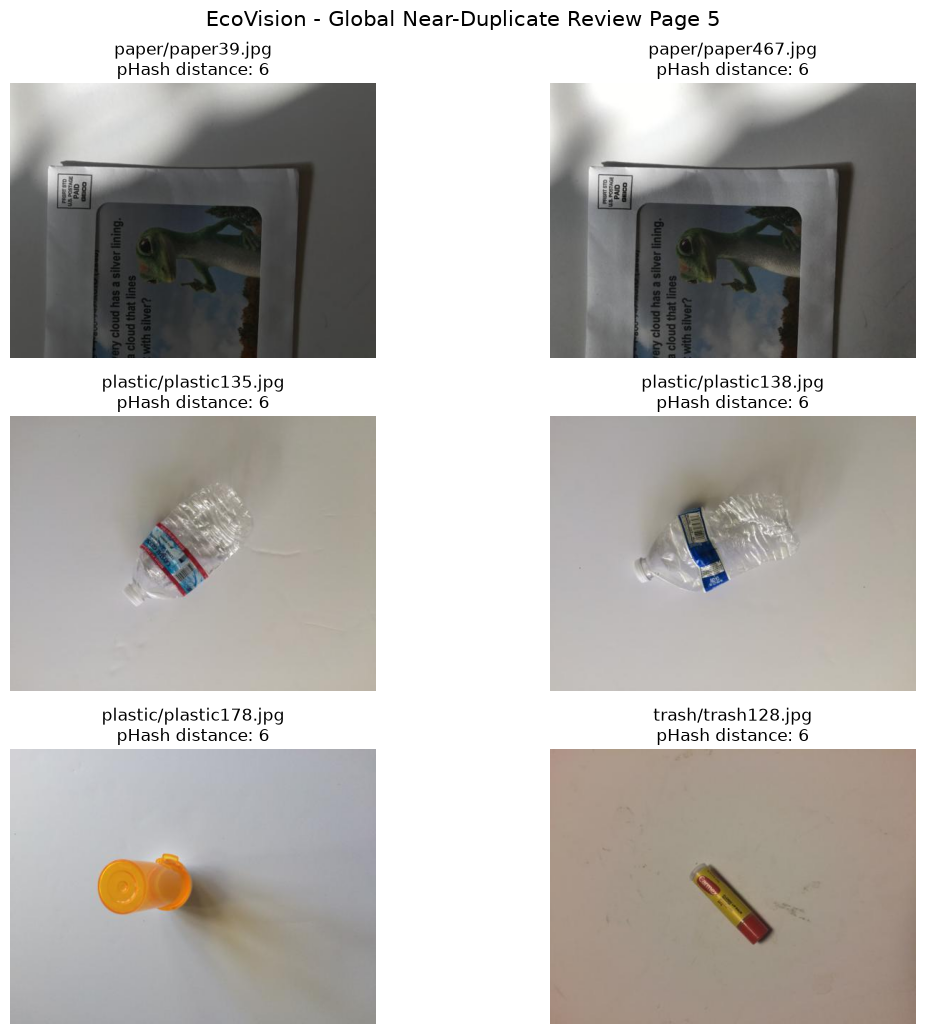

Showing candidates 21 to 23 of 23


In [23]:

from PIL import Image
import matplotlib.pyplot as plt

# Hanya tampilkan kandidat yang belum direview
pending_review = pending_global.sort_values(
    ["distance", "image_a", "image_b"]
).reset_index(drop=True)

PER_PAGE = 5
PAGE = 4

start = PAGE * PER_PAGE
batch = pending_review.iloc[start:start + PER_PAGE]

if batch.empty:
    print("Tidak ada kandidat pada halaman ini.")
else:
    fig, axes = plt.subplots(
        len(batch),
        2,
        figsize=(12, 3.5 * len(batch)),
        squeeze=False
    )

    for i, (_, row) in enumerate(batch.iterrows()):
        for col, suffix in enumerate(["a", "b"]):
            image_path = data_dir / row[f"image_{suffix}"]

            with Image.open(image_path) as img:
                axes[i, col].imshow(img.convert("RGB"))

            axes[i, col].set_title(
                f"{row[f'image_{suffix}']}\n"
                f"pHash distance: {row['distance']}"
            )
            axes[i, col].axis("off")

    plt.suptitle(
        f"EcoVision - Global Near-Duplicate Review Page {PAGE + 1}",
        fontsize=15
    )
    plt.tight_layout()
    plt.show()

print(
    f"Showing candidates {start + 1} to "
    f"{min(start + PER_PAGE, len(pending_review))} "
    f"of {len(pending_review)}"
)


In [24]:

import pandas as pd

# Review tambahan: 23 pasangan dari Page 1-5
additional_decisions = [
    # Page 1
    ("paper/paper305.jpg", "paper/paper308.jpg", "group"),
    ("cardboard/cardboard386.jpg", "cardboard/cardboard72.jpg", "group"),
    ("metal/metal155.jpg", "metal/metal6.jpg", "uncertain_group"),
    ("metal/metal159.jpg", "plastic/plastic11.jpg", "different"),
    ("paper/paper147.jpg", "paper/paper99.jpg", "group"),

    # Page 2
    ("paper/paper152.jpg", "paper/paper392.jpg", "group"),
    ("paper/paper246.jpg", "paper/paper349.jpg", "group"),
    ("paper/paper314.jpg", "paper/paper53.jpg", "group"),
    ("paper/paper522.jpg", "paper/paper534.jpg", "group"),
    ("paper/paper540.jpg", "paper/paper56.jpg", "group"),

    # Page 3
    ("metal/metal120.jpg", "metal/metal50.jpg", "group"),
    ("metal/metal154.jpg", "plastic/plastic10.jpg", "different"),
    ("paper/paper135.jpg", "paper/paper496.jpg", "group"),
    ("paper/paper180.jpg", "paper/paper284.jpg", "group"),
    ("paper/paper457.jpg", "paper/paper553.jpg", "group"),

    # Page 4
    ("paper/paper68.jpg", "paper/paper74.jpg", "group"),
    ("metal/metal122.jpg", "metal/metal57.jpg", "group"),
    ("paper/paper136.jpg", "paper/paper148.jpg", "group"),
    ("paper/paper240.jpg", "paper/paper306.jpg", "group"),
    ("paper/paper265.jpg", "paper/paper408.jpg", "group"),

    # Page 5
    ("paper/paper39.jpg", "paper/paper467.jpg", "group"),
    ("plastic/plastic135.jpg", "plastic/plastic138.jpg", "uncertain_group"),
    ("plastic/plastic178.jpg", "trash/trash128.jpg", "different"),
]

new_review_df = pd.DataFrame(
    additional_decisions,
    columns=["image_a", "image_b", "decision"]
)

def pair_keys(frame):
    return {
        frozenset((r.image_a, r.image_b))
        for r in frame.itertuples(index=False)
    }

# Verifikasi 23 keputusan tambahan
assert len(new_review_df) == 23
assert pair_keys(new_review_df) == pair_keys(pending_global)

# Gabungkan dengan 19 review sebelumnya
final_review_df = pd.concat(
    [
        review_df[["image_a", "image_b", "decision"]],
        new_review_df
    ],
    ignore_index=True
)

# Seluruh 42 kandidat global harus tercakup
assert len(final_review_df) == len(global_df) == 42
assert len(pair_keys(final_review_df)) == 42
assert pair_keys(final_review_df) == pair_keys(global_df)

final_review_df["review_basis"] = "provisional_visual_review"

# Simpan ke repository
final_review_path = (
    repo_root / "ml" / "data" /
    "global_near_duplicate_review.csv"
)

final_review_df.to_csv(final_review_path, index=False)

print("Total reviewed:", len(final_review_df))
print("\nReview decisions:")
print(final_review_df["decision"].value_counts())

print("\nSaved:", final_review_path)


Total reviewed: 42

Review decisions:
decision
group              32
different           7
uncertain_group     3
Name: count, dtype: int64

Saved: E:\PROJECT\ecovision-flutter-ml\ml\data\global_near_duplicate_review.csv


In [25]:

from sklearn.model_selection import train_test_split
import pandas as pd

RANDOM_STATE = 42

final_manifest = (
    clean_manifest
    .sort_values("path")
    .reset_index(drop=True)
    .copy()
)

# Union-Find untuk membangun kelompok objek
parent = {
    path: path for path in final_manifest["path"]
}

def find(path):
    if parent[path] != path:
        parent[path] = find(parent[path])
    return parent[path]

def union(a, b):
    root_a = find(a)
    root_b = find(b)

    if root_a != root_b:
        parent[max(root_a, root_b)] = min(root_a, root_b)

# Gabungkan foto yang sama atau belum pasti
for row in final_review_df.itertuples(index=False):
    if row.decision in ("group", "uncertain_group"):
        assert row.image_a in parent
        assert row.image_b in parent
        union(row.image_a, row.image_b)

final_manifest["group_id"] = (
    final_manifest["path"].map(find)
)

# Setiap grup harus memiliki satu label kelas
label_check = final_manifest.groupby(
    "group_id"
)["label"].nunique()

assert (label_check == 1).all(), (
    "Konflik label dalam satu grup!"
)

# Representasi satu baris per grup
group_table = final_manifest.groupby(
    "group_id", as_index=False
).agg(
    label=("label", "first"),
    n_images=("path", "size")
)

# Split berdasarkan grup dengan stratifikasi label
train_val_g, test_g = train_test_split(
    group_table,
    test_size=0.15,
    stratify=group_table["label"],
    random_state=RANDOM_STATE
)

train_g, val_g = train_test_split(
    train_val_g,
    test_size=0.15 / 0.85,
    stratify=train_val_g["label"],
    random_state=RANDOM_STATE
)

# Mapping group -> split
split_mapping = {}

for name, frame in [
    ("train", train_g),
    ("val", val_g),
    ("test", test_g),
]:
    for gid in frame["group_id"]:
        split_mapping[gid] = name

final_manifest["split"] = (
    final_manifest["group_id"].map(split_mapping)
)

assert final_manifest["split"].notna().all()
assert len(final_manifest) == 2524
assert final_manifest["sha256"].is_unique

# Verifikasi seluruh pasangan yang sudah direview
path_to_split = dict(zip(
    final_manifest["path"],
    final_manifest["split"]
))

verification = final_review_df.copy()

verification["cross_split"] = [
    path_to_split[r.image_a] != path_to_split[r.image_b]
    for r in verification.itertuples(index=False)
]

should_group = verification["decision"].isin(
    ["group", "uncertain_group"]
)

assert not verification.loc[
    should_group, "cross_split"
].any(), "Group leakage detected!"

# Kandidat pHash yang masih melintasi split
# harus merupakan pasangan yang sudah dinilai berbeda
remaining_cross = verification[
    verification["cross_split"]
]

assert (
    remaining_cross["decision"] == "different"
).all()

# Simpan split final, tanpa menimpa split sementara
final_split_dir = report_dir / "splits_grouped_final"
final_split_dir.mkdir(parents=True, exist_ok=True)

final_splits = {}

for name in ("train", "val", "test"):
    frame = final_manifest[
        final_manifest["split"] == name
    ].copy()

    final_splits[name] = frame
    frame.to_csv(
        final_split_dir / f"{name}.csv",
        index=False
    )

verification.to_csv(
    final_split_dir / "review_verification.csv",
    index=False
)

# Tampilkan hasil aktual
distribution = pd.DataFrame({
    name: frame["label"].value_counts()
    for name, frame in final_splits.items()
}).fillna(0).astype(int).sort_index()

distribution["total"] = distribution.sum(axis=1)

print("Total images:", len(final_manifest))
print("Total groups:", len(group_table))

for name, frame in final_splits.items():
    percent = 100 * len(frame) / len(final_manifest)
    print(f"{name}: {len(frame)} ({percent:.2f}%)")

print("\nClass distribution:")
print(distribution)

print("\nGrouped candidate leakage: NONE")
print("Exact duplicate leakage: NONE")
print("Reviewed cross-split pHash pairs:",
      len(remaining_cross))
print("Unreviewed pHash pairs: 0")
print("\nSaved:", final_split_dir)


Total images: 2524
Total groups: 2489
train: 1766 (69.97%)
val: 378 (14.98%)
test: 380 (15.06%)

Class distribution:
           train  val  test  total
label                             
cardboard    282   61    60    403
glass        350   75    75    500
metal        287   61    61    409
paper        417   88    89    594
plastic      335   72    74    481
trash         95   21    21    137

Grouped candidate leakage: NONE
Exact duplicate leakage: NONE
Reviewed cross-split pHash pairs: 3
Unreviewed pHash pairs: 0

Saved: E:\PROJECT\ecovision-flutter-ml\ml\reports\generated\splits_grouped_final


In [26]:

import json
import pandas as pd

# Simpan manifest split final yang reproducible
tracked_dir = repo_root / "ml" / "data" / "splits" / "v1"
tracked_dir.mkdir(parents=True, exist_ok=True)

columns = ["path", "label", "sha256", "group_id", "split"]

assert set(columns).issubset(final_manifest.columns)

for split_name in ("train", "val", "test"):
    frame = (
        final_manifest.loc[
            final_manifest["split"] == split_name,
            columns
        ]
        .sort_values("path")
        .reset_index(drop=True)
    )

    frame.to_csv(
        tracked_dir / f"{split_name}.csv",
        index=False
    )

# Verifikasi ulang file yang disimpan
saved = pd.concat(
    [
        pd.read_csv(tracked_dir / f"{name}.csv")
        for name in ("train", "val", "test")
    ],
    ignore_index=True
)

assert len(saved) == 2524
assert saved["path"].is_unique
assert saved["sha256"].is_unique
assert saved.groupby("group_id")["split"].nunique().max() == 1
assert set(saved["label"]) == {
    "cardboard", "glass", "metal",
    "paper", "plastic", "trash"
}

metadata = {
    "version": "v1",
    "dataset": "TrashNet",
    "random_state": 42,
    "phash_threshold": 6,
    "total_images": len(saved),
    "total_groups": saved["group_id"].nunique(),
    "split_counts": saved["split"].value_counts().to_dict(),
    "review_status": "provisional_visual_review"
}

with open(tracked_dir / "metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2)

print("Saved and verified:", tracked_dir)
print(saved["split"].value_counts())


Saved and verified: E:\PROJECT\ecovision-flutter-ml\ml\data\splits\v1
split
train    1766
test      380
val       378
Name: count, dtype: int64
